# 03 · Experiment A — calibration under the null (RQ1, H1a and H1b)

**Question.** When there is no signal at all, how often does each probe wrongly declare "signal"? A well-calibrated test at α = 0.05 should do so in about 5 % of null datasets.

**Hypotheses**

* **H1a.** Every permutation-wrapped probe keeps its false-positive rate (FPR) within the binomial 95 % interval around α.
* **H1b.** Per-feature tests combined *without* multiple-testing correction ("reject if any feature has p ≤ α") exceed α, increasingly so as the number of features grows; Simes/Benjamini–Hochberg aggregation restores control.

**Design**

| Part | What is tested | Settings | Replicates | Null distribution |
|---|---|---|---|---|
| A1 | Exact, dataset-specific permutation tests for the probes S1–S4, G1–G3, M1, M2 | n ∈ {200, 1000} × positive rate ∈ {0.5, 0.1}; 25 features | 60 per setting, B = 100 permutations | label permutation |
| A1b | Same for the expensive probes M3 (forest) and M4 (gradient boosting) | n = 200, balanced; 25 features | 30, B = 40 | label permutation |
| A2 | Uncorrected vs. Simes aggregation of per-feature tests (S1, S2) | p ∈ {10, 50, 200} features × n ∈ {200, 1000}; balanced | 300 per setting | S2 analytic; S1 Monte Carlo |

Replicate numbers are set by the compute budget (two CPU cores, see paper Section IV). With 60 replicates, the 95 % interval for an observed FPR of 5 % is roughly 1–14 %, so A1 is a coarse check; A2 is precise.

In [1]:
import json
def load_library_source(path="01_probe_library.ipynb"):
    """Concatenate the code cells of the library notebook so they can be executed here."""
    nb = json.load(open(path, encoding="utf-8"))
    return "\n\n".join("".join(c["source"]) for c in nb["cells"] if c["cell_type"] == "code")

_LIBRARY_IMPORT = True
exec(compile(load_library_source(), "probe_library", "exec"))

def clopper_pearson(k, n, level=0.95):
    """Exact binomial confidence interval for a proportion k/n."""
    a = 1 - level
    lo = stats.beta.ppf(a / 2, k, n - k + 1) if k > 0 else 0.0
    hi = stats.beta.ppf(1 - a / 2, k + 1, n - k) if k < n else 1.0
    return lo, hi

## A1 — exact permutation tests on null data

In [2]:
CHEAP = [MutualInformationProbe(), AnovaChi2Probe(), DistanceCorrelationProbe(), HSICProbe(),
         FisherRatioProbe(), BorderlineProbe(), NearestNeighbourErrorProbe(),
         ModelProbe("tree", "M1_Tree"), ModelProbe("logreg", "M2_LogReg")]
EXPENSIVE = [ModelProbe("forest", "M3_Forest"), ModelProbe("hgb", "M4_HGB")]

def a1_job(n, pos_rate, rep, probes, B):
    d = make_synthetic("null", n, n_noise=20, pos_rate=pos_rate, seed=100_000 + 1000 * rep + n + int(100 * pos_rate))
    rows = []
    for pr in probes:
        r = run_probe(pr, d, B=B, seed=rep)
        r.update({"n": n, "pos_rate": pos_rate, "rep": rep, "B": B})
        rows.append(r)
    return rows

cache = os.path.join(RESULTS_DIR, "expA1_permutation_null.csv")
if os.path.exists(cache):
    a1 = pd.read_csv(cache)
else:
    jobs = [(n, pr, rep, CHEAP, 100) for n in (200, 1000) for pr in (0.5, 0.1) for rep in range(60)]
    jobs += [(200, 0.5, rep, EXPENSIVE, 40) for rep in range(30)]
    out = Parallel(n_jobs=2)(delayed(a1_job)(*j) for j in jobs)
    a1 = pd.DataFrame([r for rows in out for r in rows])
    a1.to_csv(cache, index=False)
print("A1 rows:", len(a1))

A1 rows: 2220


In [3]:
def fpr_table(df, by):
    """False-positive rate with exact 95% interval, grouped by `by`."""
    rows = []
    for key, g in df.groupby(by):
        k, n = int((g.p <= ALPHA).sum()), len(g)
        lo, hi = clopper_pearson(k, n)
        rows.append(dict(zip(by, key if isinstance(key, tuple) else (key,)),
                         rejections=k, replicates=n, FPR=k / n, CI_low=lo, CI_high=hi,
                         calibrated=lo <= ALPHA <= hi))
    return pd.DataFrame(rows)

a1_fpr = fpr_table(a1, ["probe", "n", "pos_rate"])
a1_fpr["probe"] = pd.Categorical(a1_fpr.probe, PROBE_ORDER, ordered=True)
a1_fpr = a1_fpr.sort_values(["probe", "n", "pos_rate"])
a1_fpr.to_csv(os.path.join(RESULTS_DIR, "expA1_fpr.csv"), index=False)
a1_fpr.round(3)

,probe,n,pos_rate,rejections,replicates,FPR,CI_low,CI_high,calibrated
22,S1_MI,200,0.1,0,60,0.000,0.000,0.060,True
23,S1_MI,200,0.5,0,60,0.000,0.000,0.060,True
24,S1_MI,1000,0.1,0,60,0.000,0.000,0.060,True
25,S1_MI,1000,0.5,0,60,0.000,0.000,0.060,True
26,S2_ANOVA_Chi2,200,0.1,2,60,0.033,0.004,0.115,True
27,S2_ANOVA_Chi2,200,0.5,4,60,0.067,0.018,0.162,True
28,S2_ANOVA_Chi2,1000,0.1,1,60,0.017,0.000,0.089,True
29,S2_ANOVA_Chi2,1000,0.5,4,60,0.067,0.018,0.162,True
30,S3_dCor,200,0.1,2,60,0.033,0.004,0.115,True
31,S3_dCor,200,0.5,6,60,0.100,0.038,0.205,True


In [4]:
pooled = fpr_table(a1, ["probe"])
pooled["probe"] = pd.Categorical(pooled.probe, PROBE_ORDER, ordered=True)
pooled = pooled.sort_values("probe")
print("Pooled over settings, the FPR interval contains 0.05 for",
      int(pooled.calibrated.sum()), "of", len(pooled), "probes.")
pooled.round(3)

Pooled over settings, the FPR interval contains 0.05 for 10 of 11 probes.


,probe,rejections,replicates,FPR,CI_low,CI_high,calibrated
7,S1_MI,0,240,0.000,0.000,0.015,False
8,S2_ANOVA_Chi2,11,240,0.046,0.023,0.081,True
9,S3_dCor,13,240,0.054,0.029,0.091,True
10,S4_HSIC,13,240,0.054,0.029,0.091,True
0,G1_F1,9,240,0.038,0.017,0.070,True
1,G2_N1,13,240,0.054,0.029,0.091,True
2,G3_N3,14,240,0.058,0.032,0.096,True
3,M1_Tree,8,240,0.033,0.014,0.065,True
4,M2_LogReg,14,240,0.058,0.032,0.096,True
5,M3_Forest,3,30,0.100,0.021,0.265,True


### p-value uniformity

Under H₀ an exact test produces p-values that are (discretely) uniform. The QQ-style plot compares the empirical distribution of A1 p-values with the uniform line.

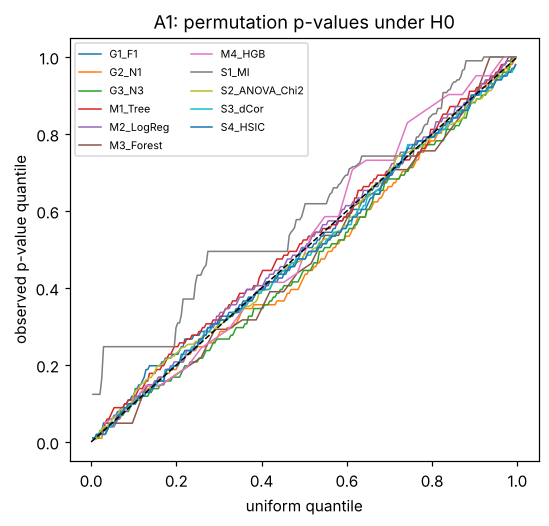

In [5]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(5.5, 5))
for name, g in a1.groupby("probe"):
    p = np.sort(g.p.to_numpy())
    ax.plot(np.arange(1, len(p) + 1) / (len(p) + 1), p, lw=1, label=name)
ax.plot([0, 1], [0, 1], "k--", lw=1)
ax.set_xlabel("uniform quantile")
ax.set_ylabel("observed p-value quantile")
ax.set_title("A1: permutation p-values under H0")
ax.legend(fontsize=7, ncol=2)
plt.savefig(os.path.join(FIG_DIR, "expA1_pvalue_uniformity.png"), dpi=200, bbox_inches="tight")
plt.show()

## A2 — multiple testing: uncorrected vs. Simes aggregation

S2 provides analytic per-feature p-values. For S1 (mutual information) the per-feature null distribution is simulated: because all synthetic features are i.i.d. standard normal, the null MI values of all features in 100 separate null datasets are pooled into one reference distribution per setting.

In [6]:
def a2_job(n, p_total, rep):
    d = make_synthetic("null", n, n_noise=p_total - N_INFORMATIVE, seed=500_000 + 7 * rep + n + p_total)
    p_s2 = AnovaChi2Probe().pvalues(d, d.y)
    mi = MutualInformationProbe().stat(d, d.y)
    return {"n": n, "p": p_total, "rep": rep, "s2_pvals": p_s2, "mi": mi}

cache = os.path.join(RESULTS_DIR, "expA2_multiple_testing.csv")
if os.path.exists(cache):
    a2 = pd.read_csv(cache)
else:
    rows = []
    for n in (200, 1000):
        for p_total in (10, 50, 200):
            ref = Parallel(n_jobs=2)(delayed(a2_job)(n, p_total, 10_000 + r) for r in range(100))
            null_mi = np.concatenate([r["mi"] for r in ref])
            reps = Parallel(n_jobs=2)(delayed(a2_job)(n, p_total, r) for r in range(300))
            for r in reps:
                p_s1 = np.array([mc_pvalue(v, null_mi) for v in r["mi"]])
                for probe, pv in (("S1_MI", p_s1), ("S2_ANOVA_Chi2", r["s2_pvals"])):
                    rows.append({"probe": probe, "n": n, "p": p_total, "rep": r["rep"],
                                 "reject_uncorrected": bool(pv.min() <= ALPHA),
                                 "reject_simes": bool(simes(pv) <= ALPHA)})
    a2 = pd.DataFrame(rows)
    a2.to_csv(cache, index=False)

a2_tab = (a2.groupby(["probe", "n", "p"])
            .agg(FPR_uncorrected=("reject_uncorrected", "mean"), FPR_simes=("reject_simes", "mean"),
                 replicates=("rep", "size")).reset_index())
a2_tab["theory_uncorrected"] = 1 - (1 - ALPHA) ** a2_tab.p   # if features were independent
a2_tab.to_csv(os.path.join(RESULTS_DIR, "expA2_fpr.csv"), index=False)
a2_tab.round(3)

,probe,n,p,FPR_uncorrected,FPR_simes,replicates,theory_uncorrected
0,S1_MI,200,10,0.413,0.033,300,0.401
1,S1_MI,200,50,0.903,0.047,300,0.923
2,S1_MI,200,200,1.000,0.090,300,1.000
3,S1_MI,1000,10,0.357,0.017,300,0.401
4,S1_MI,1000,50,0.947,0.030,300,0.923
5,S1_MI,1000,200,1.000,0.027,300,1.000
6,S2_ANOVA_Chi2,200,10,0.410,0.033,300,0.401
7,S2_ANOVA_Chi2,200,50,0.943,0.037,300,0.923
8,S2_ANOVA_Chi2,200,200,1.000,0.063,300,1.000
9,S2_ANOVA_Chi2,1000,10,0.403,0.060,300,0.401


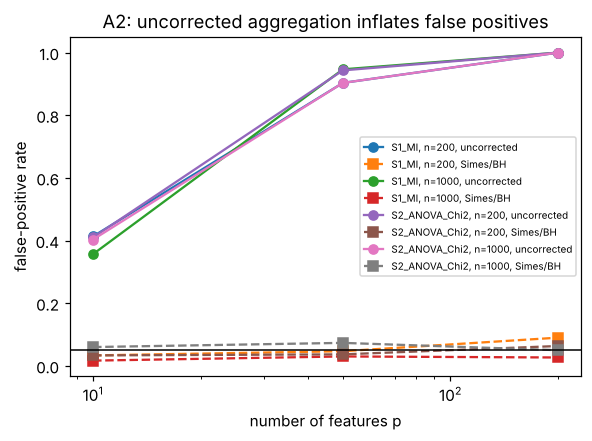

In [7]:
fig, ax = plt.subplots(figsize=(6, 4))
for (probe, n), g in a2_tab.groupby(["probe", "n"]):
    ax.plot(g.p, g.FPR_uncorrected, "o-", label=f"{probe}, n={n}, uncorrected")
    ax.plot(g.p, g.FPR_simes, "s--", label=f"{probe}, n={n}, Simes/BH")
ax.axhline(ALPHA, color="k", lw=1)
ax.set_xscale("log")
ax.set_xlabel("number of features p")
ax.set_ylabel("false-positive rate")
ax.set_title("A2: uncorrected aggregation inflates false positives")
ax.legend(fontsize=6.5)
plt.savefig(os.path.join(FIG_DIR, "expA2_multiple_testing.png"), dpi=200, bbox_inches="tight")
plt.show()

## Summary printed for the paper

In [8]:
print("A1 pooled FPR by probe:")
print(pooled[["probe", "FPR", "CI_low", "CI_high", "replicates"]].round(3).to_string(index=False))
print("\nA2 (p = 200 features):")
print(a2_tab[a2_tab.p == 200][["probe", "n", "FPR_uncorrected", "FPR_simes"]].round(3).to_string(index=False))

A1 pooled FPR by probe:
        probe   FPR  CI_low  CI_high  replicates
        S1_MI 0.000   0.000    0.015         240
S2_ANOVA_Chi2 0.046   0.023    0.081         240
      S3_dCor 0.054   0.029    0.091         240
      S4_HSIC 0.054   0.029    0.091         240
        G1_F1 0.038   0.017    0.070         240
        G2_N1 0.054   0.029    0.091         240
        G3_N3 0.058   0.032    0.096         240
      M1_Tree 0.033   0.014    0.065         240
    M2_LogReg 0.058   0.032    0.096         240
    M3_Forest 0.100   0.021    0.265          30
       M4_HGB 0.033   0.001    0.172          30

A2 (p = 200 features):
        probe    n  FPR_uncorrected  FPR_simes
        S1_MI  200              1.0      0.090
        S1_MI 1000              1.0      0.027
S2_ANOVA_Chi2  200              1.0      0.063
S2_ANOVA_Chi2 1000              1.0      0.050
